# Data exploration: banknote authentication

Goal: understand the data before training anything. Each section says why we look at it. Run from the `notebooks/` folder.

## 1. Setup
Import our own data code from `src/` so the notebook uses exactly the same loading and splitting as the experiments.

In [2]:
import sys
import numpy as np
import matplotlib.pyplot as plt

sys.path.append("..")  # lets us import from src/ (the notebook lives one folder down)
from src.data import load_banknote, stratified_split, standardise
from src.ann import NeuralNetwork
from src.metrics import accuracy

FEATURES = ["variance", "skewness", "curtosis", "entropy"]  # column order in the UCI file
X, y = load_banknote("../data/data_banknote_authentication.txt")

## 2. Basic checks
Why: confirm the file loaded correctly (1372 rows, 4 features) and has no missing values, before trusting any result.

In [3]:
print("shape:", X.shape, "labels:", y.shape)
print("missing values:", int(np.isnan(X).sum()))
for i, name in enumerate(FEATURES):
    col = X[:, i]
    print(f"{name:9s} min={col.min():7.2f} max={col.max():7.2f} mean={col.mean():6.2f} std={col.std():5.2f}")

shape: (1372, 4) labels: (1372,)
missing values: 0
variance  min=  -7.04 max=   6.82 mean=  0.43 std= 2.84
skewness  min= -13.77 max=  12.95 mean=  1.92 std= 5.87
curtosis  min=  -5.29 max=  17.93 mean=  1.40 std= 4.31
entropy   min=  -8.55 max=   2.45 mean= -1.19 std= 2.10


## 3. Class balance
Why: if one class dominates, accuracy can look good by always guessing it. The majority-class rate is the baseline a trained network must beat.

genuine (0): 762  forged (1): 610
majority-class baseline accuracy: 0.555


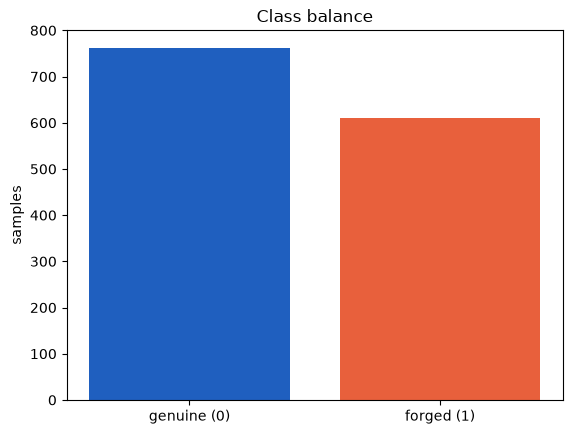

In [4]:
counts = np.bincount(y)
print("genuine (0):", counts[0], " forged (1):", counts[1])
print(f"majority-class baseline accuracy: {counts.max() / len(y):.3f}")

plt.bar(["genuine (0)", "forged (1)"], counts, color=["#1F5FBF", "#E8603C"])
plt.ylabel("samples")
plt.title("Class balance")
plt.show()

## 4. Feature distributions by class
Why: shows which features separate the classes and whether the scales differ (this justifies standardising).

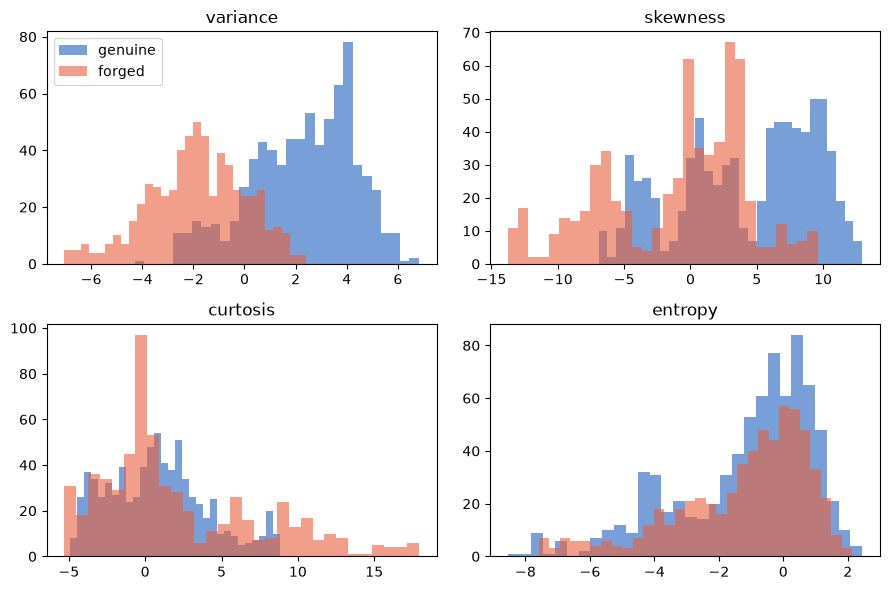

In [5]:
fig, axes = plt.subplots(2, 2, figsize=(9, 6))
for i, ax in enumerate(axes.ravel()):
    ax.hist(X[y == 0, i], bins=30, alpha=0.6, label="genuine", color="#1F5FBF")
    ax.hist(X[y == 1, i], bins=30, alpha=0.6, label="forged", color="#E8603C")
    ax.set_title(FEATURES[i])
axes[0, 0].legend()
plt.tight_layout()
plt.show()

## 5. Two features against each other
Why: a quick look at how separable the classes are. Clear clusters mean a small network should reach very high accuracy.

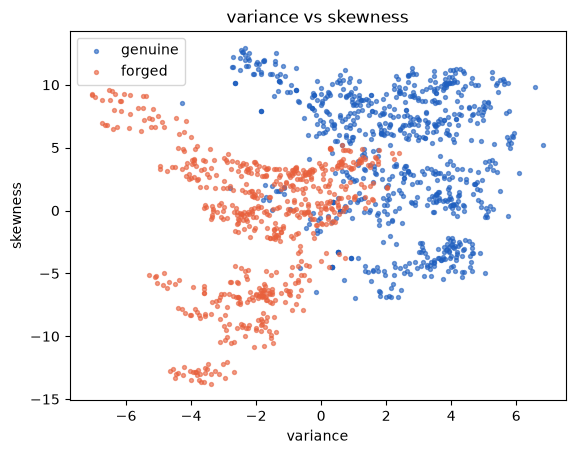

In [6]:
plt.scatter(X[y == 0, 0], X[y == 0, 1], s=8, alpha=0.6, label="genuine", color="#1F5FBF")
plt.scatter(X[y == 1, 0], X[y == 1, 1], s=8, alpha=0.6, label="forged", color="#E8603C")
plt.xlabel("variance")
plt.ylabel("skewness")
plt.legend()
plt.title("variance vs skewness")
plt.show()

## 6. Train/test split check
Why: the split must keep the class proportions, and standardising must use training statistics only (no test leakage).

In [7]:
X_train, X_test, y_train, y_test = stratified_split(X, y, test_ratio=0.3, seed=0)
print("train:", len(y_train), "forged rate", round(y_train.mean(), 3))
print("test: ", len(y_test), "forged rate", round(y_test.mean(), 3))

X_train_s, X_test_s = standardise(X_train, X_test)
print("train mean after scaling (should be ~0):", X_train_s.mean(axis=0).round(3))
print("train std  after scaling (should be ~1):", X_train_s.std(axis=0).round(3))
print("test mean  after scaling (close to 0 but not exact):", X_test_s.mean(axis=0).round(3))

train: 960 forged rate 0.445
test:  412 forged rate 0.444
train mean after scaling (should be ~0): [ 0. -0. -0. -0.]
train std  after scaling (should be ~1): [1. 1. 1. 1.]
test mean  after scaling (close to 0 but not exact): [-0.017  0.121 -0.07  -0.08 ]


## 7. What does a random network score?
Why: PSO starts from random networks, so this is its starting point. Random weights often land far from 50% because the data separates easily and a random network can be confidently right or confidently inverted.

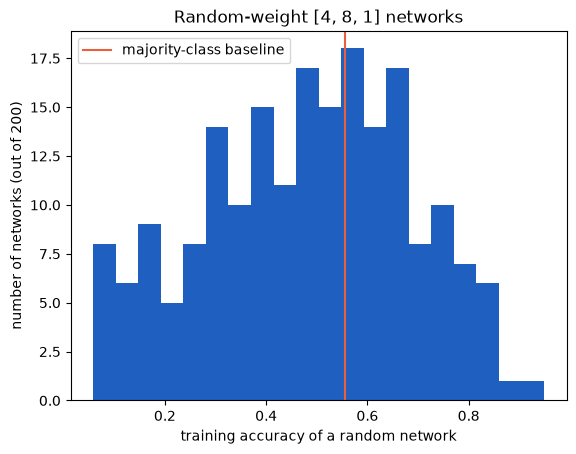

best random: 0.949  worst random: 0.058  mean: 0.481


In [8]:
scores = []
for seed in range(200):
    net = NeuralNetwork([4, 8, 1], ["tanh", "logistic"], seed=seed)
    scores.append(accuracy(y_train, net.predict(X_train_s)))

plt.hist(scores, bins=20, color="#1F5FBF")
plt.axvline(counts.max() / len(y), color="#E8603C", label="majority-class baseline")
plt.xlabel("training accuracy of a random network")
plt.ylabel("number of networks (out of 200)")
plt.legend()
plt.title("Random-weight [4, 8, 1] networks")
plt.show()
print(f"best random: {max(scores):.3f}  worst random: {min(scores):.3f}  mean: {np.mean(scores):.3f}")